# 전자출결 시계열 — 선택근무 장려금·근로시간 점검 (실행 노트북)

REPORT.md 의 수치·그래프·캘린더 리포트를 이 노트북 한 번 실행으로 재현한다. 계산은 `src/` 모듈을 그대로 호출한다.

순서: ① 데이터 생성 → ② 출결 엔진 교차검증 → ③ 정제·일별 패널 → ④ 주·정산기간 집계 → ⑤ 단축 요일 선호(누적·이동창) → ⑥ 그래프 → ⑦ 2026 장려금 판정 → ⑧ 캘린더 리포트·관리판 데이터

In [1]:
import sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
pd.set_option("display.width", 160)
import generate_data, analysis

## ① 합성 데이터 생성
9 to 6 사무직 17명 + 선택근무 참여자 7명(장일 9시간·단축일 4시간, 근무계획표), 2025-07 ~ 2026-06

In [2]:
generate_data.main()
logs, emps, leave, hol, plan = analysis.load()
logs.head()

출퇴근 기록 5,620건, 근무계획 1,715일, 연차 188건, 직원 24명 → /home/claude/flex-work-timeseries/data


,emp_id,d,in,out,edited,edit_reason
0,E01,2025-07-01,2025-07-01T08:52:00+09:00,2025-07-01T20:08:00+09:00,0,
1,E02,2025-07-01,2025-07-01T08:46:00+09:00,2025-07-01T19:05:00+09:00,0,
2,E03,2025-07-01,2025-07-01T08:50:00+09:00,2025-07-01T19:04:00+09:00,0,
3,E04,2025-07-01,2025-07-01T08:50:00+09:00,2025-07-01T19:07:00+09:00,0,
4,E05,2025-07-01,2025-07-01T08:53:00+09:00,2025-07-01T19:00:00+09:00,0,


In [3]:
plan.assign(ym=plan.date.str[:7], plan_min=plan.plan_min.astype(int)).groupby(["emp_id","ym"]).agg(days=("plan","size"), plan_h=("plan_min", lambda x: x.sum()/60)).assign(required_h=lambda d: d.days*8).head(6)  # 월 계획 합계 = 근무일 × 8시간

days  plan_h  required_h
emp_id ym                               
E01    2025-07    23   184.0         184
       2025-08    20   160.0         160
       2025-09    22   176.0         176
       2025-10    18   144.0         144
       2025-11    20   160.0         160
       2025-12    22   176.0         176

## ② 출결 엔진 교차검증 (이음24 원본 JS ↔ Python)

In [4]:
print(subprocess.run([sys.executable, "src/verify_engine.py"], capture_output=True, text=True).stdout)

교차검증 22,424건 중 불일치 0건



## ③ 기본 정보·정제(결측·이상치)·일별 패널

In [5]:
analysis.profile(logs, emps, leave, plan)

{'rows': 5620,
 'columns': ['emp_id', 'd', 'in', 'out', 'edited', 'edit_reason'],
 'employees': 24,
 'groups': {'일반': 17, '지원대상': 7},
 'period': ['2025-07-01', '2026-06-30'],
 'days_with_records': 245,
 'blank_out': 38,
 'edited_records': 33,
 'leave_days': 188,
 'plan_days': 1715,
 'emp_days_multi': 14}

In [6]:
usable, flagged, flags = analysis.clean(logs)
flags

{'정상': 5564, '퇴근 미기록(결측)': 38, '오입력(10분 미만)': 14, '이상치(16시간 이상 체류)': 4}

In [7]:
p = analysis.build_panel(usable, flagged, emps, leave, hol, plan)
p.groupby(["category", "status"]).size().unstack(fill_value=0)

status,근무,누락,연차
category,,,
일반,3927,21,135
지원대상,1637,25,53


In [8]:
p[p.miss_type != ""].groupby(["category", "miss_type"]).size().unstack(fill_value=0)

miss_type,16시간 이상 체류,기록 없음,사후입력,퇴근 미기록
category,,,,
일반,4,3,13,14
지원대상,0,1,20,24


## ④ 주·정산기간(월) 집계 — 리샘플링
누락일은 소정에서 빼고 ① 누락으로만 센다.

In [9]:
w = analysis.weekly(p); m = analysis.monthly(p, w)
m.groupby("category")["level"].value_counts().unstack(fill_value=0)

level,미지급,정상,조치 필요,주의,확인 필요
category,,,,,
일반,0,164,0,32,4
지원대상,3,51,30,0,0


In [10]:
m[m.category == "지원대상"].pivot(index="alias", columns="ym", values="level").fillna("").replace({"정상": "·", "조치 필요": "△", "미지급": "×"})

ym,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06
alias,,,,,,,,,,,,
(가상)강예린,·,·,·,·,×,·,·,·,×,·,·,·
(가상)김하늘,·,△,·,·,·,·,△,·,·,△,·,·
(가상)박서연,·,△,△,·,·,·,·,·,·,△,·,·
(가상)이도윤,·,·,·,·,·,△,△,·,△,·,·,·
(가상)정지우,△,·,·,△,△,△,△,△,△,·,△,△
(가상)조현우,△,△,△,△,△,△,×,△,△,△,△,△
(가상)최민준,·,·,·,·,·,·,△,·,·,·,·,·


## ⑤ 단축 요일 선호 — 주별 선택 → 월 누적 비중(expanding) → 8주 이동창(rolling)

In [11]:
wsel, share, pref = analysis.short_pref(p)
pref.assign(top=pref.top.map(lambda i: "월화수목금"[i]))

,emp_id,top,top_share,roll_min,roll_last,first_month_share,stable_from
0,E01,금,0.953,0.667,1.000,1.000,2025-07
1,E02,금,0.762,0.500,0.800,0.750,2025-07
2,E03,월,0.568,0.250,0.833,0.250,2025-11
3,E04,수,0.767,0.400,0.833,1.000,2025-09
4,E05,목,0.558,0.143,0.500,0.667,2025-09
5,E06,금,0.905,0.667,1.000,1.000,2025-09
6,E07,금,0.780,0.571,0.667,1.000,2025-11


In [12]:
share.loc["E03"].rename(columns=dict(enumerate("월화수목금"))).round(2)  # 박서연: 월요일 비중이 몇 달 뒤에 굳어지는지

dow,월,화,수,목,금
ym,,,,,
2025-07,0.25,0.0,0.0,0.0,0.75
2025-08,0.50,0.0,0.0,0.0,0.50
2025-09,0.45,0.0,0.0,0.0,0.55
2025-10,0.50,0.0,0.0,0.0,0.50
2025-11,0.56,0.0,0.0,0.0,0.44
2025-12,0.50,0.0,0.0,0.0,0.50
2026-01,0.54,0.0,0.0,0.0,0.46
2026-02,0.52,0.0,0.0,0.0,0.48
2026-03,0.52,0.0,0.0,0.0,0.48


## ⑥ 그래프·분해·예측·results.json (analysis.main)

In [13]:
analysis.main()
res = json.loads((ROOT / "results.json").read_text(encoding="utf-8"))
res["short_weekday_share"], res["friday_absent_avg"], res["timeseries"]["forecast_mae"]

{
 "profile": {
  "rows": 5620,
  "columns": [
   "emp_id",
   "d",
   "in",
   "out",
   "edited",
   "edit_reason"
  ],
  "employees": 24,
  "groups": {
   "일반": 17,
   "지원대상": 7
  },
  "period": [
   "2025-07-01",
   "2026-06-30"
  ],
  "days_with_records": 245,
  "blank_out": 38,
  "edited_records": 33,
  "leave_days": 188,
  "plan_days": 1715,
  "emp_days_multi": 14
 },
 "cleaning": {
  "정상": 5564,
  "퇴근 미기록(결측)": 38,
  "오입력(10분 미만)": 14,
  "이상치(16시간 이상 체류)": 4
 },
 "by_category": {
  "지원대상": {
   "emp_months": 84,
   "workers": 7,
   "level": {
    "정상": 51,
    "조치 필요": 30,
    "미지급": 3
   },
   "r_missing": 22,
   "r_hours": 8,
   "r_short": 13,
   "any": 33,
   "missing_total": 45,
   "missing_by_type": {
    "기록 없음": 1,
    "퇴근 미기록": 24,
    "16시간 이상 체류": 0,
    "사후입력": 20
   },
   "workers_with_issue": {
    "E07": 12,
    "E05": 9,
    "E01": 3,
    "E02": 3,
    "E03": 3,
    "E06": 2,
    "E04": 1
   },
   "late": 16,
   "ot_h": 107.2,
   "over52_weeks": 0
  },
  "일반": {


({'월': 0.144, '수': 0.111, '목': 0.104, '금': 0.641},
 3.9,
 {'전체 평균': 1.25, '지난주 같은 요일': 0.76, '최근 8주 요일 평균': 0.53})

In [14]:
pd.DataFrame(res["timeseries"]["monthly_change"])  # 전월 대비 변화율 (0 → n 은 빈칸)

,ym,missing,short,missing_mom_pct,short_mom_pct
0,2025-07,1,27,NaN,NaN
1,2025-08,4,22,300.0,-19.0
2,2025-09,2,26,-50.0,18.0
3,2025-10,0,20,-100.0,-23.0
4,2025-11,10,27,NaN,35.0
5,2025-12,2,28,-80.0,4.0
6,2026-01,5,25,150.0,-11.0
7,2026-02,3,20,-40.0,-20.0
8,2026-03,11,27,267.0,35.0
9,2026-04,2,28,-82.0,4.0


01_short_weekday_weekly.png


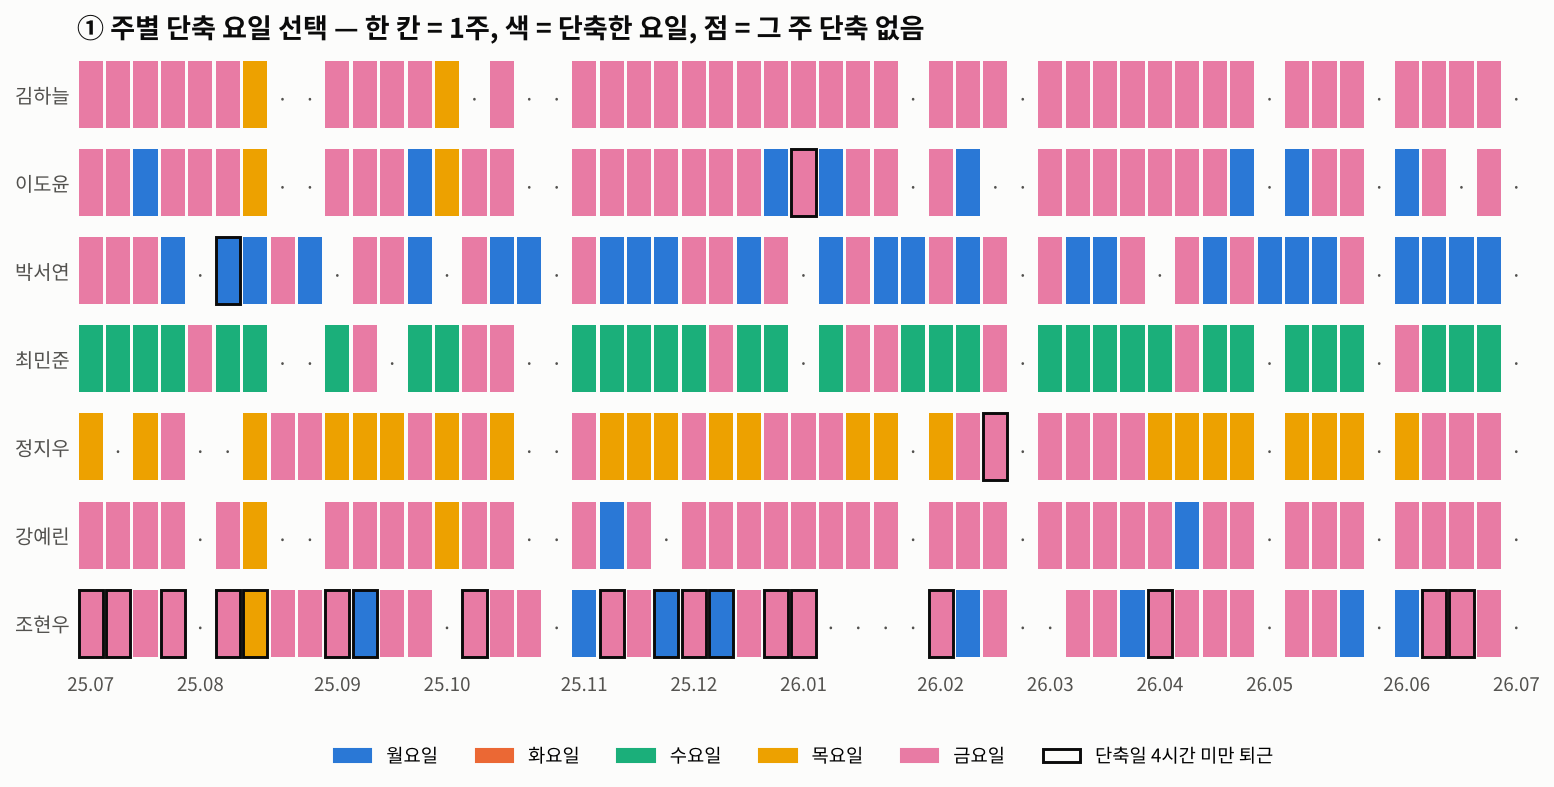

02_short_weekday_cumulative.png


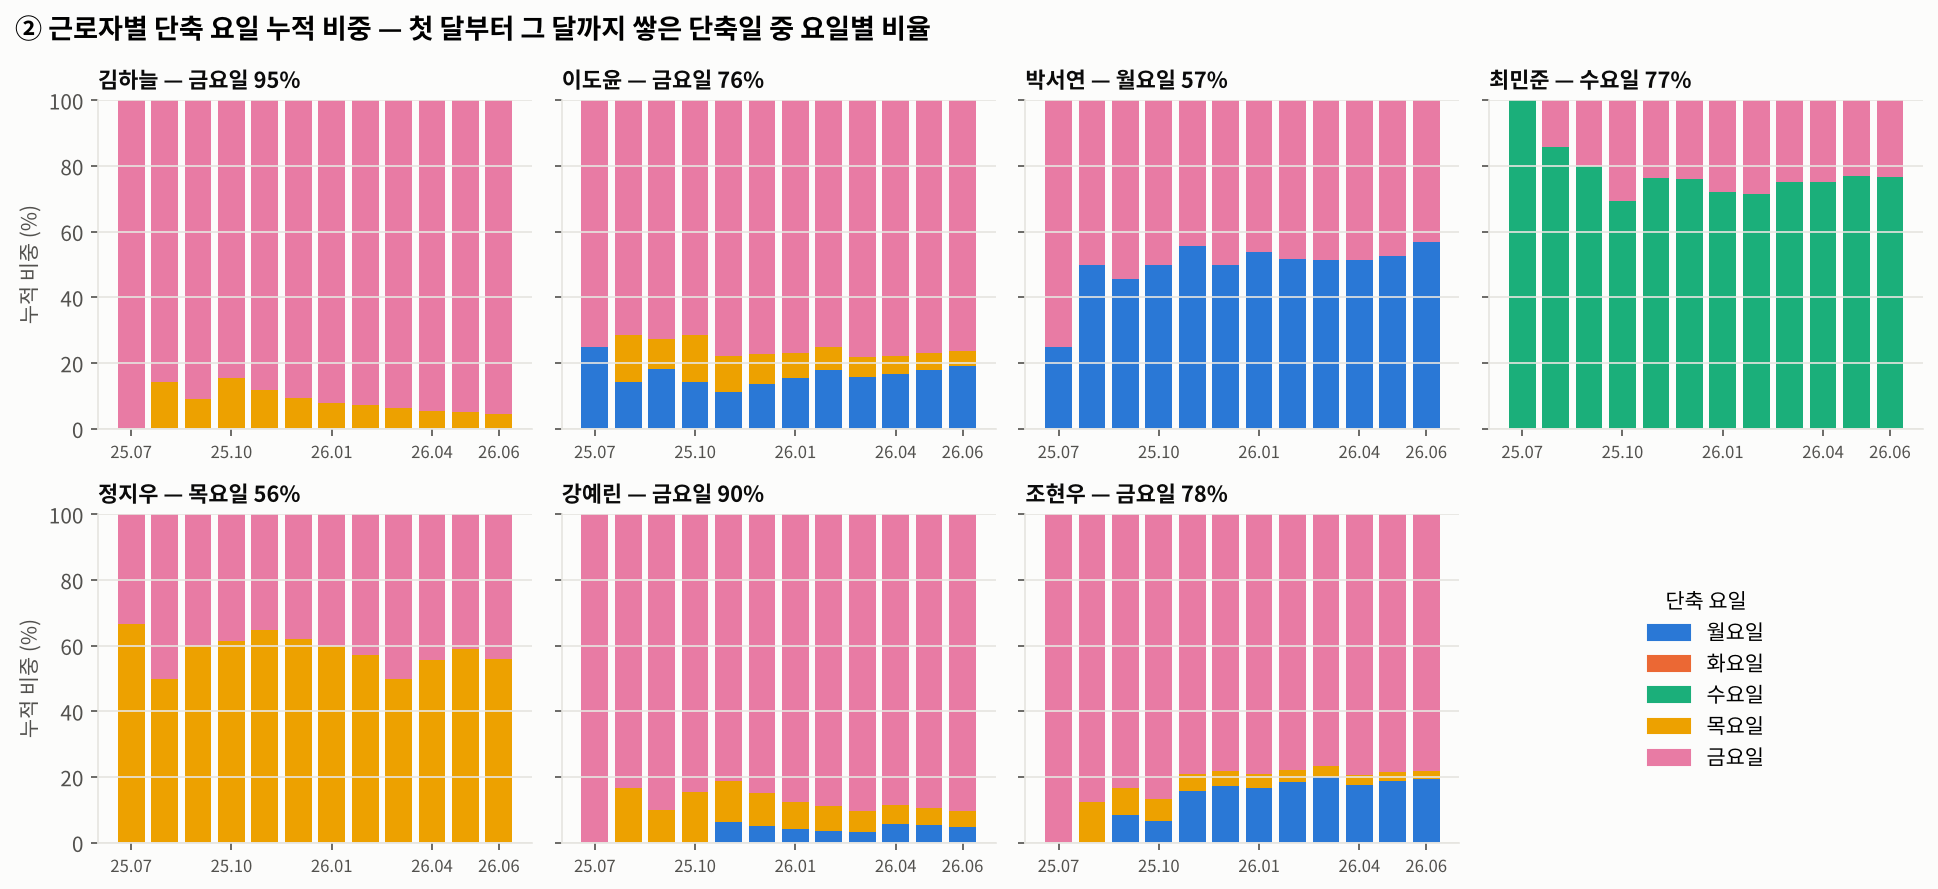

03_short_weekday_by_month.png


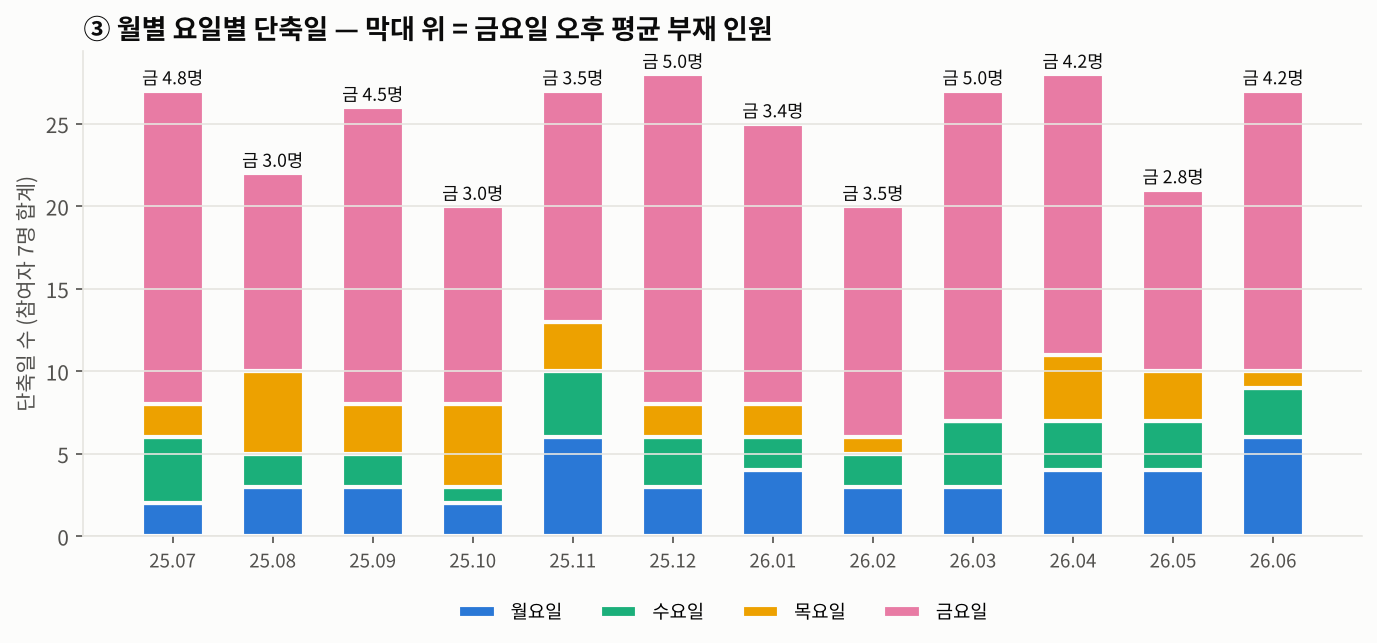

06_decomposition.png


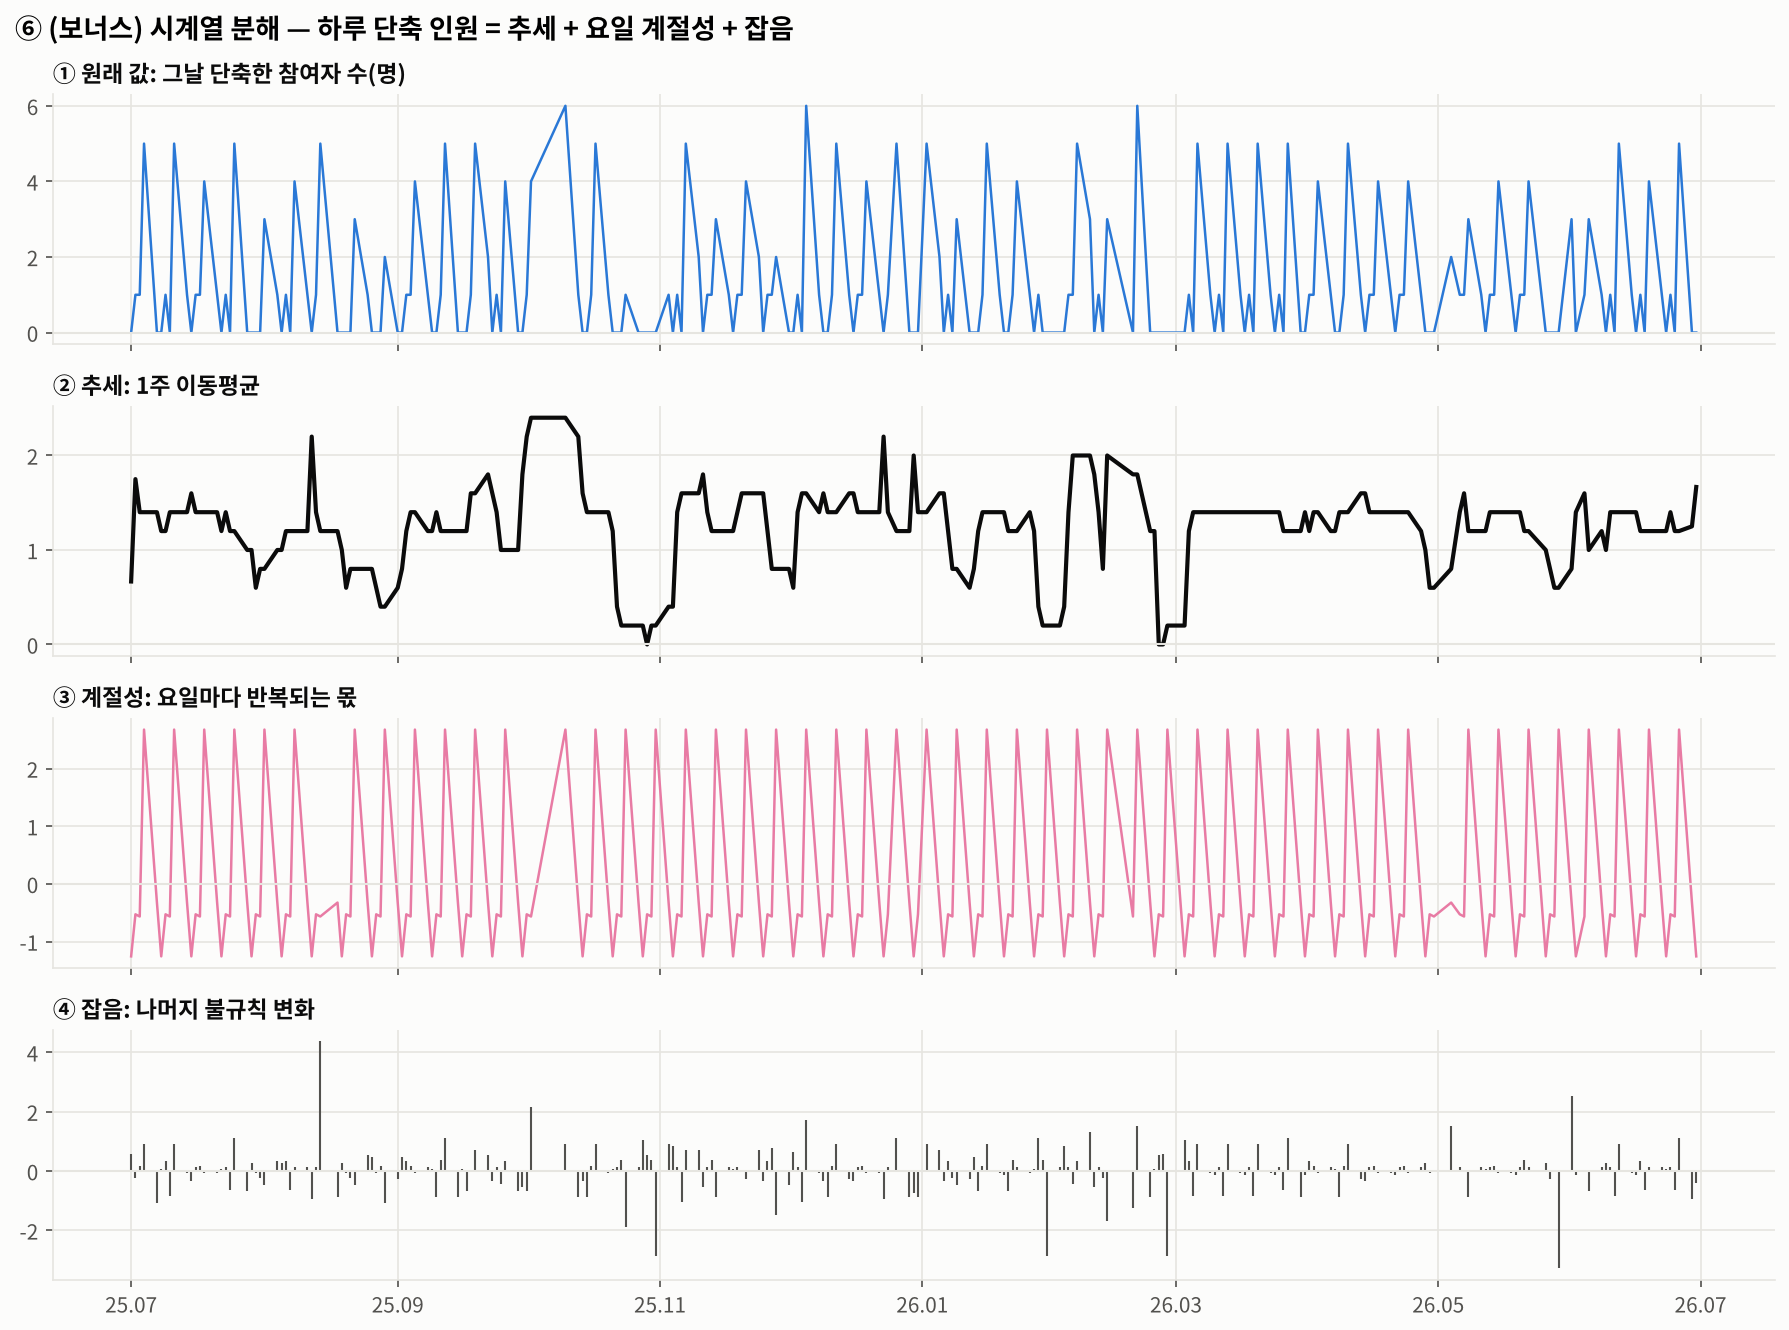

07_baseline_forecast.png


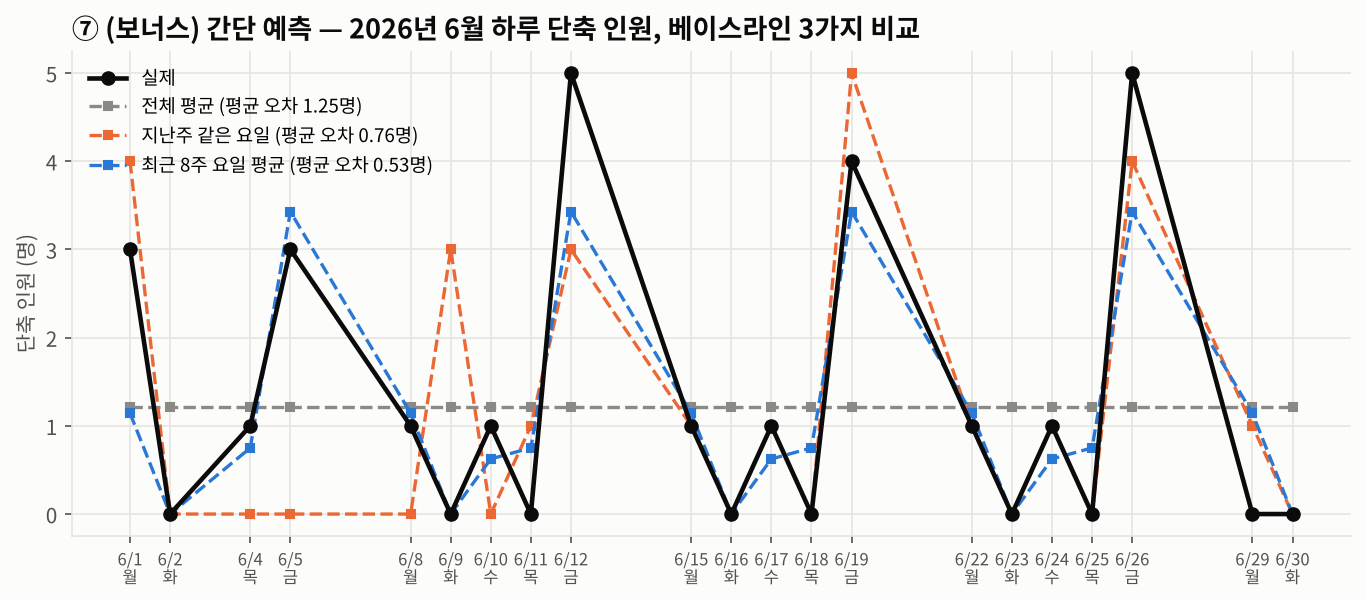

In [15]:
from IPython.display import Image, display
for f_ in res["images"]:
    print(f_); display(Image(filename=str(ROOT / "images" / f_), width=820))

## ⑦ 2026 장려금 판정·회차별 금액·명부 점검

In [16]:
import eligibility
eligibility.main()

{
 "months": 84,
 "paid_months": 81,
 "level": {
  "정상": 51,
  "조치 필요": 30,
  "미지급": 3
 },
 "expected_won": 24300000,
 "max_won": 25200000,
 "lost_won": 900000,
 "fails": [
  {
   "emp_id": "E06",
   "alias": "(가상)강예린",
   "ym": "2025-11",
   "fail_reasons": "출결 누락 월 5회 이상",
   "cut_h": 7.95,
   "missing": 8
  },
  {
   "emp_id": "E06",
   "alias": "(가상)강예린",
   "ym": "2026-03",
   "fail_reasons": "출결 누락 월 5회 이상",
   "cut_h": 15.75,
   "missing": 7
  },
  {
   "emp_id": "E07",
   "alias": "(가상)조현우",
   "ym": "2026-01",
   "fail_reasons": "단축 6시간 미달",
   "cut_h": 4.58,
   "missing": 3
  }
 ],
 "rounds": [
  {
   "round": 1,
   "won": 6300000,
   "lost": 0
  },
  {
   "round": 2,
   "won": 6000000,
   "lost": 300000
  },
  {
   "round": 3,
   "won": 5700000,
   "lost": 600000
  },
  {
   "round": 4,
   "won": 6300000,
   "lost": 0
  }
 ],
 "headcount": {
  "insured_prev_yearend": 24,
  "cap": 7,
  "designated": 7
 }
}


04_participant_monthly_status.png


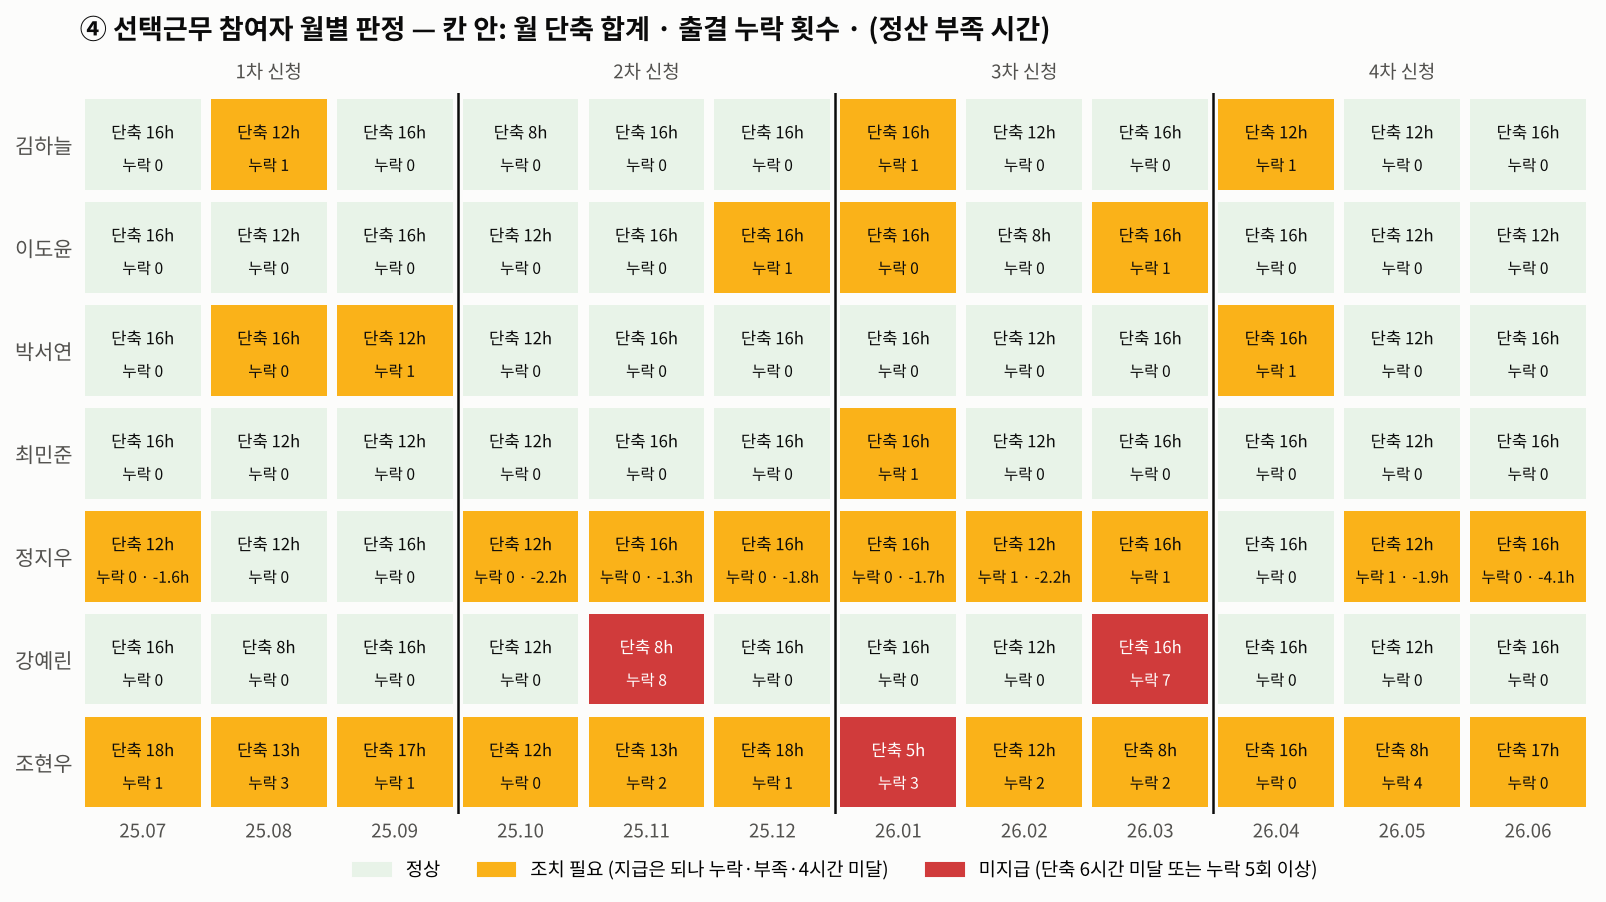

05_monthly_cut_hours.png


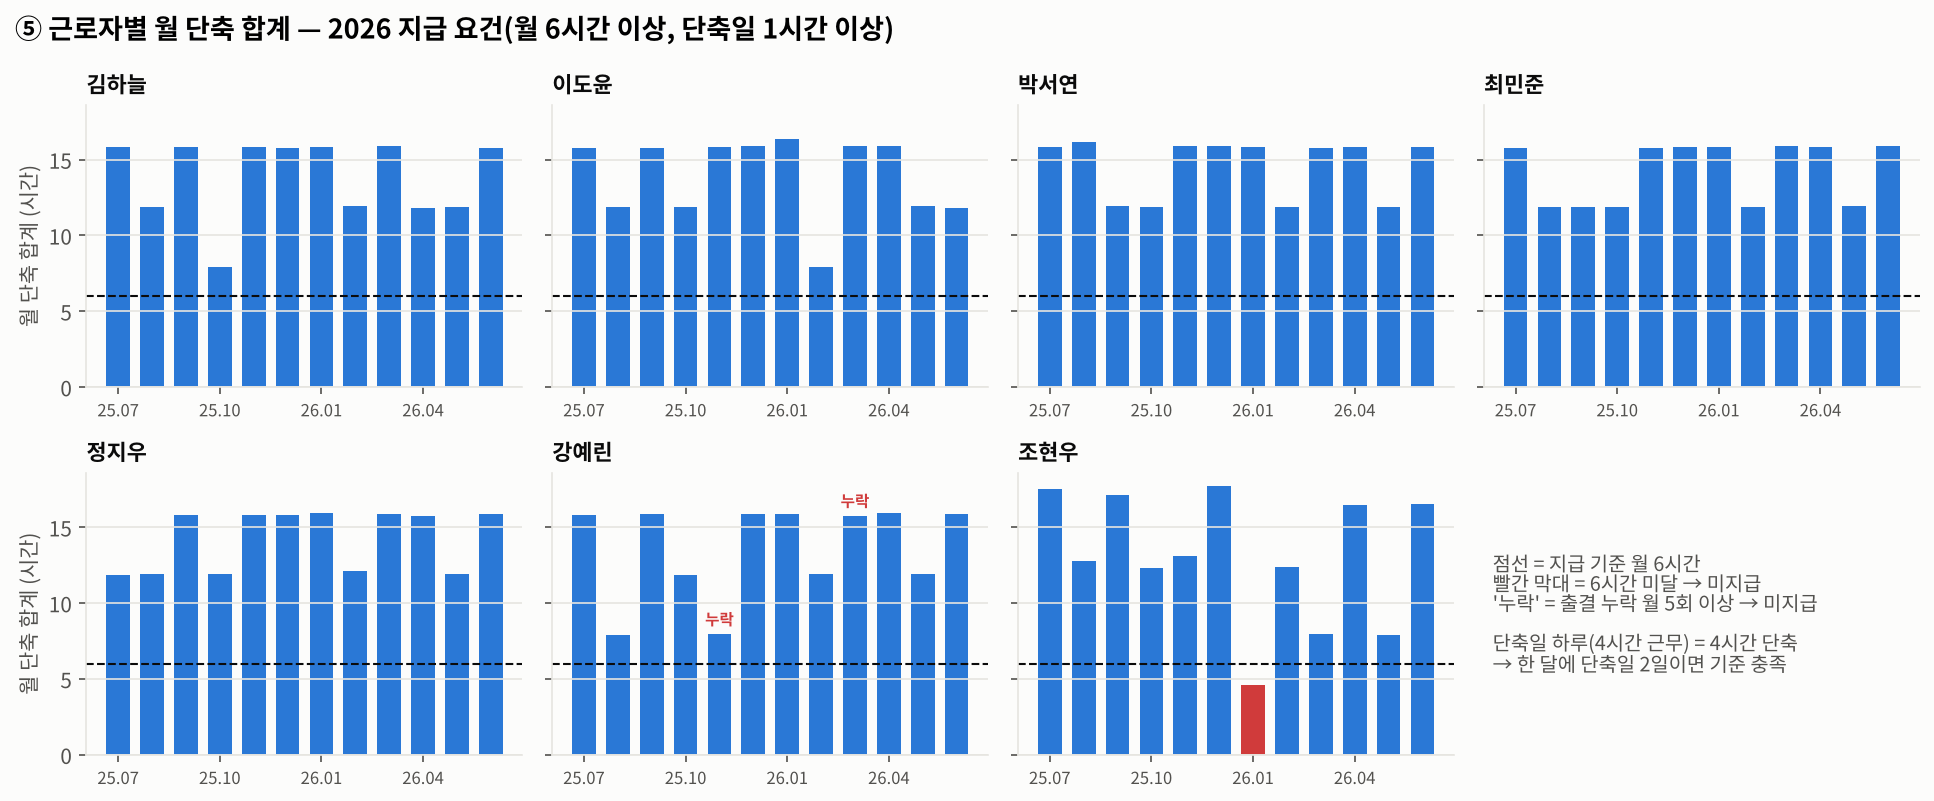

In [17]:
el = json.loads((ROOT / "results_eligibility.json").read_text(encoding="utf-8"))
for f_ in el["images"]:
    print(f_); display(Image(filename=str(ROOT / "images" / f_), width=820))

## ⑧ 근로자별 월 캘린더 리포트·기업 보고서·관리판 데이터

In [18]:
import build_reports
build_reports.main.__globals__["sys"].argv = ["build_reports.py"]
build_reports.main()
print((ROOT / "reports" / "company_progress_report.md").read_text(encoding="utf-8")[:1800])

근로자 리포트 24개, 기업 보고서, data.js (1198 KB)
# 선택근무·근태 점검 보고 — (가상)디딤테크 (2026년 6월 기준, 4차 신청 회차)

> 2026 선택근무 장려금: 월 6시간 이상 단축(1일 8시간 대비 1시간 이상 단축한 날만) · 출결 누락 월 5회 이상이면 그 달 미지급 · 1인 월 30만원(1년 최대 360만원)
> 근무시간표: 일반 09:00~18:00 (휴게 12~13시) · 1일 8시간 · 주 40시간 / 선택근무 장일 09:00~19:00(9시간) · 단축일 09:00~13:30(휴게 12:00~12:30, 4시간) · 통상 09:00~18:00(8시간) — 근무계획표 기준, 정산기간 1개월
> 합성 데이터 (src/generate_data.py, seed 20261018) — 실제 인물·기업 아님. 계산은 판단 보조용이며 지급 여부는 고용센터 심사로 결정됩니다.

## 1. 4차 신청 회차 판정 (2026-04 ~ 2026-06)

| 근로자 | 선호 단축 요일 | 4월 | 5월 | 6월 | 신청 금액 | 조치 |
|---|---|---|---|---|---:|---|
| (가상)김하늘 | 금요일 95% | △ 지급·조치 | ○ 지급 | ○ 지급 | 900,000원 | 4월 출결 누락 1회 정정 신청 |
| (가상)이도윤 | 금요일 76% | ○ 지급 | ○ 지급 | ○ 지급 | 900,000원 | – |
| (가상)박서연 | 월요일 57% | △ 지급·조치 | ○ 지급 | ○ 지급 | 900,000원 | 4월 출결 누락 1회 정정 신청 |
| (가상)최민준 | 수요일 77% | ○ 지급 | ○ 지급 | ○ 지급 | 900,000원 | – |
| (가상)정지우 | 목요일 56% | ○ 지급 | △ 지급·조치 | △ 지급·조치 | 900,000원 | 5월 출결 누락 1회 정정 신청; 5월 정산기간 근무시간 1시간 56분 부족; 6월 정산기간 근무시간 4시간 8분 부족 |
| (가상)강예린 | 금요일 90% | ○ 지급

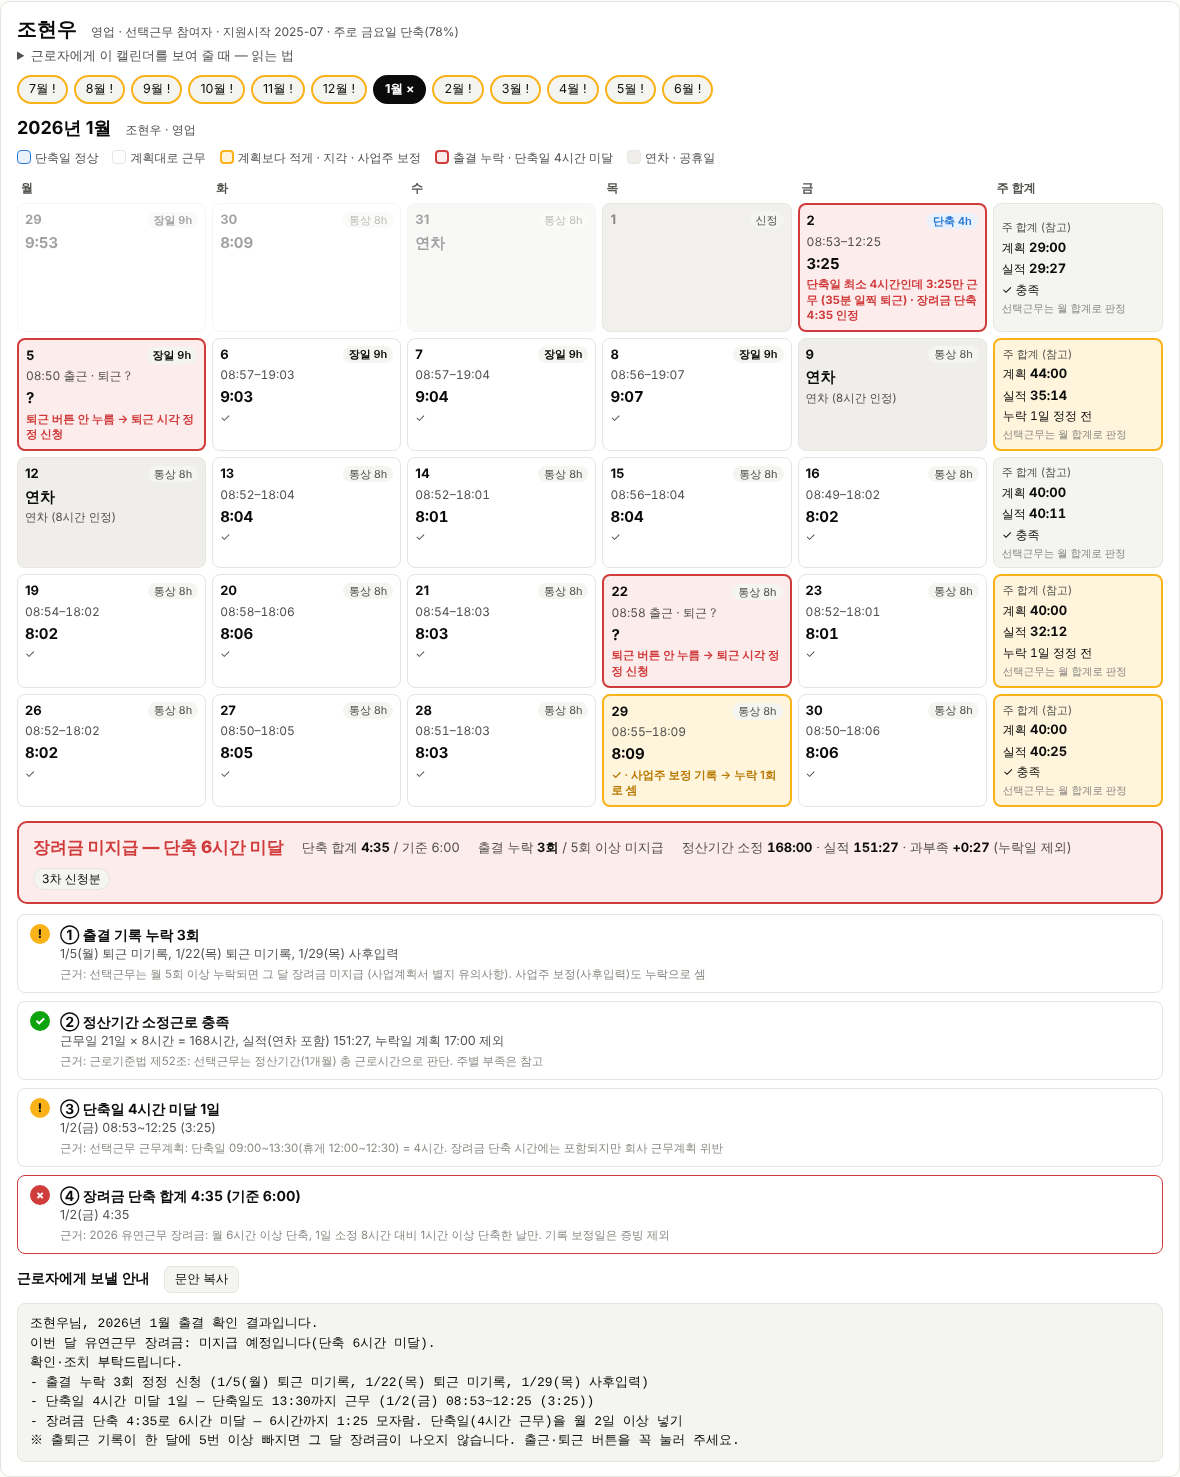

In [19]:
display(Image(filename=str(ROOT / "docs" / "screenshots" / "scenario_flex_calendar_E07_2026-01.png"), width=820))